In [45]:
import pandas as pd
import numpy as np
from ta.momentum import RSIIndicator
import plotly.express as px

In [19]:
df = pd.read_csv("harmonia-20.1-82-2024-market-16months.zip")
df.head()

,index,open_price,high,low,close,harmonia_prediction
0,2023-09-05 02:40:00,1619.05,1620.16,1617.49,1619.00,-0.025
1,2023-09-05 02:45:00,1619.01,1620.10,1618.35,1618.85,-0.021
2,2023-09-05 02:50:00,1618.86,1619.64,1618.85,1619.23,-0.009
3,2023-09-05 02:55:00,1619.22,1620.15,1618.06,1618.24,0.007
4,2023-09-05 03:00:00,1618.24,1618.58,1614.29,1616.31,0.001


In [96]:
window = 2
df["std_open_price"] = df["open_price"].rolling(window=window).std()
df["std_harmonia_prediction"] = df["harmonia_prediction"].rolling(window=window).std()
df_2 = df[:-window].dropna()

In [97]:
print("Correlation:",np.corrcoef(df_2["std_open_price"],df_2["std_harmonia_prediction"]))

Correlation: [[1.         0.69919838]
 [0.69919838 1.        ]]


In [51]:
df["variation_open_price"] = (df["open_price"].shift(-1) - df["open_price"])/(df["open_price"].shift(-1))
df["variation_harmonia"] = (df["harmonia_prediction"].shift(-1) - df["harmonia_prediction"])

In [55]:
df_2 = df[:-window].dropna()
print("Correlation:",np.corrcoef(df_2["variation_open_price"],df_2["variation_harmonia"]))

Correlation: [[1.         0.79029483]
 [0.79029483 1.        ]]


In [58]:
X = df_2["variation_open_price"]
y = df_2["variation_harmonia"]
coeffs = np.polyfit(X, y, 1)

a, b = coeffs  # a = pente, b = intercept
print(f"Équation : y = {a:.4f}x + {b:.4f}")


Équation : y = 22.0219x + -0.0001


In [60]:
def f(x,a,b):
    return a*x+b
df_2["variation_prédite"] = f(df_2["variation_open_price"],22.0219,-0.0001)

In [92]:
value = 0.1
df_2["error_variation_predite_harmonia"] = np.abs(df_2["variation_prédite"] - df_2["variation_harmonia"])
error_threshold = np.percentile(df_2["error_variation_predite_harmonia"], 100 - value)
print(f"Minimum error value to be in the top {value}%: {error_threshold}")
df_2["bool_error_variation_predite_harmonia"] = df_2["error_variation_predite_harmonia"] >= error_threshold
df_high_error = df_2[df_2["bool_error_variation_predite_harmonia"]]  # Filter data


Minimum error value to be in the top 0.1%: 0.20560216594490713


In [101]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
# Create figure
fig = go.Figure()

# Create a subplot figure with 2 rows
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=("Open Price", "Harmonia Prediction"))

# === First subplot: Open Price ===
fig.add_trace(go.Scatter(
    x=df_2["index"], 
    y=df_2["open_price"], 
    mode='lines', 
    name='Open Price', 
    line=dict(color='black')
), row=1, col=1)

# Add blue dots where error is high
fig.add_trace(go.Scatter(
    x=df_high_error["index"], 
    y=df_high_error["open_price"], 
    mode='markers', 
    name='High Error Points',
    marker=dict(color='blue', size=8)
), row=1, col=1)

# === Second subplot: Harmonia Prediction ===
fig.add_trace(go.Scatter(
    x=df_2["index"], 
    y=df_2["harmonia_prediction"], 
    mode='lines', 
    name='Harmonia Prediction', 
    line=dict(color='red')
), row=2, col=1)

# Add blue dots for high error points
fig.add_trace(go.Scatter(
    x=df_high_error["index"], 
    y=df_high_error["harmonia_prediction"], 
    mode='markers', 
    name='High Error Points (Harmonia)',
    marker=dict(color='blue', size=8)
), row=2, col=1)

# Update layout
fig.update_layout(
    title="Open Price and Harmonia Prediction with High Error Points",
    xaxis2_title="Time",  # X-axis label for second plot
    yaxis_title="Open Price",
    yaxis2_title="Harmonia Prediction",
    height=700,  # Adjust figure height
    showlegend=True
)

# Show plot
fig.show("browser")


Ouverture dans une session de navigateur existante.


Mean Squared Error (MSE): 0.000942
R² Score: 0.6545


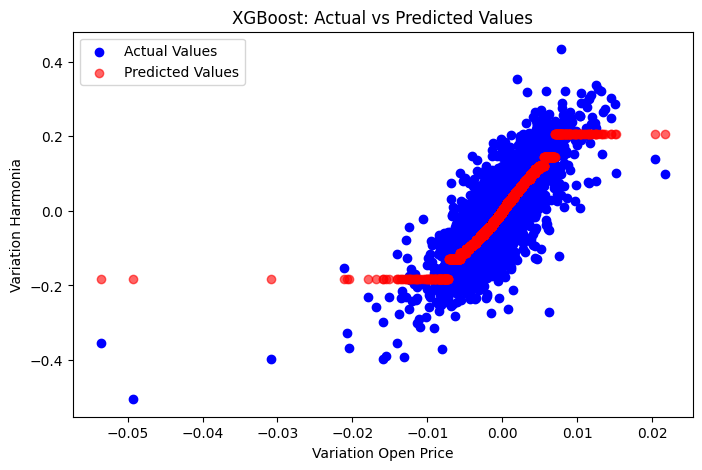

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1️⃣ Prepare Data
X = df_2[["variation_open_price"]]  # Features (must be a 2D array)
y = df_2["variation_harmonia"]  # Target

# 2️⃣ Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3️⃣ Train XGBoost Model
model = XGBRegressor(n_estimators=500, learning_rate=0.2, max_depth=5, random_state=42)
model.fit(X_train, y_train)

# 4️⃣ Make Predictions
y_pred = model.predict(X_test)

# 5️⃣ Evaluate Model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.6f}")
print(f"R² Score: {r2:.4f}")

# 6️⃣ Visualize Predictions
plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, color="blue", label="Actual Values")
plt.scatter(X_test, y_pred, color="red", label="Predicted Values", alpha=0.6)
plt.xlabel("Variation Open Price")
plt.ylabel("Variation Harmonia")
plt.title("XGBoost: Actual vs Predicted Values")
plt.legend()
plt.show()
